In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [200]:
words = open("makemore/names.txt", "r").read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [201]:
len(words)

32033

In [202]:
chars = sorted(list(set("".join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi["."] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [203]:
block_size = 3
X, Y = [], []
for w in words:
    # print(w)
    context = [0] * block_size
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print("".join(itos[i] for i in context), "--->", itos[ix])
        context = context[1:] + [ix]

X = torch.tensor(X)
Y = torch.tensor(Y)

In [204]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [205]:
g = torch.Generator().manual_seed(44)
C = torch.randn((27, 2), generator=g)

In [206]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [207]:
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)

In [208]:
h = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)

In [209]:
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)

In [210]:
logits = h @ W2 + b2

In [211]:
logits.shape

torch.Size([228146, 27])

In [212]:
counts = logits.exp()

In [213]:
prob = counts / counts.sum(1, keepdim=True)

In [ ]:
loss = -prob[torch.arange(32), Y].log().mean()

In [188]:
loss

tensor(2.3195, grad_fn=<NllLossBackward0>)

In [275]:
block_size = 4
def build_dataset(words, block_size):
    
    X, Y = [], []
    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print("".join(itos[i] for i in context), "--->", itos[ix])
            context = context[1:] + [ix]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1], block_size)
Xdev, Ydev = build_dataset(words[n1:n2], block_size)
Xte, Yte = build_dataset(words[n2:], block_size)

In [288]:
g = torch.Generator().manual_seed(44)
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((block_size * 10, 400), generator=g)
b1 = torch.randn(400, generator=g)
W2 = torch.randn((400, 200), generator=g)
b2 = torch.randn(200, generator=g)
W3 = torch.randn((200, 27), generator=g)
b3 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2, W3, b3]

In [289]:
sum(p.nelement() for p in parameters)

102297

In [290]:
for p in parameters:
    p.requires_grad=True

In [291]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [292]:
lri = []
lossi = []
stepi = []

In [293]:
from tqdm import tqdm

In [295]:
steps = 200000
lr = 0.1
for i in tqdm(range(steps)):  
    ix = torch.randint(0, Xtr.shape[0], (128,))  
    emb = C[Xtr[ix]]
    h1 = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
    h2 = torch.tanh(h1 @ W2 + b2)
    logits = h2 @ W3 + b3
    loss = F.cross_entropy(logits, Ytr[ix])
    # if not i%1:
    #     print(loss.item())

    for p in parameters:
        p.grad = None
    loss.backward()

    # lr = lrs[i]
    if i%30000 == 0 and i != 0:
        lr /= 2
    for p in parameters:
        p.data += -lr * p.grad

    # lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.log10().item())

100%|██████████| 200000/200000 [14:19<00:00, 232.67it/s]


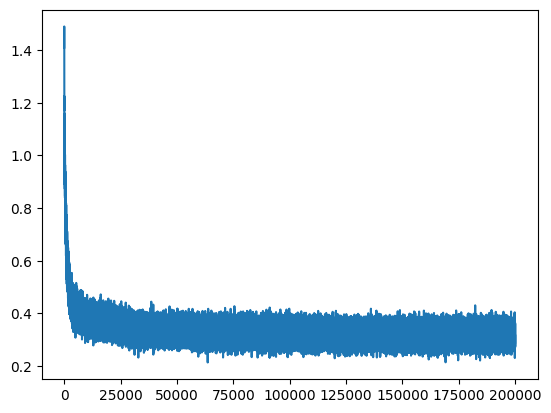

In [296]:
plt.plot(stepi, lossi)

In [301]:
emb = C[Xtr]
h1 = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
h2 = torch.tanh(h1 @ W2 + b2)
logits = h2 @ W3 + b3
loss = F.cross_entropy(logits, Ytr)

print(f"{loss=}")

loss=tensor(2.0958, grad_fn=<NllLossBackward0>)


In [302]:
emb = C[Xdev]
h1 = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
h2 = torch.tanh(h1 @ W2 + b2)
logits = h2 @ W3 + b3
loss = F.cross_entropy(logits, Ydev)

print(f"{loss=}")

loss=tensor(2.2150, grad_fn=<NllLossBackward0>)


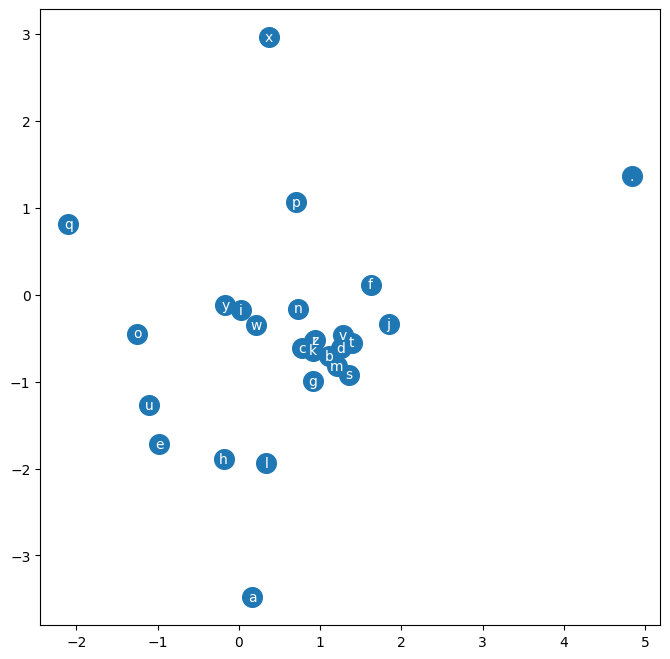

In [299]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha="center", va="center", color="white")
plt.grid="minor"

In [306]:
g = torch.Generator().manual_seed(44)
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        emb = C[torch.tensor([context])]
        h1 = torch.tanh(emb.view(emb.shape[0], -1) @ W1 + b1)
        h2 = torch.tanh(h1 @ W2 + b2)
        logits = h2 @ W3 + b3
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break

    print("".join(itos[i] for i in out))

braveona.
dol.
ashemii.
calit.
genlyn.
mamoa.
emsefonsea.
varyba.
ronja.
bavre.
canna.
toven.
nawyab.
harkyn.
nahymarisa.
duthanvaly.
krisah.
caigia.
amaliar.
jatiel.
